# Data and Features

The target is the gender label recorded in the CSV. The target and athlete ID are not model features.

## Cohort and feature versions

The source contains 423,006 rows. The analysis keeps rows with a known Female or Male label, a unique athlete ID, and valid values for all seven selected measurements. This gives one common cohort for both feature versions and all four experiments.

- Version 1: age, height, and weight.
- Version 2: version 1 plus clean-and-jerk, snatch, deadlift, and back squat.
- Model: a class-balanced decision tree.
- Split: one stratified 80/20 split with random seed 42, reused for all runs.
- Parameter sets: max depth 3 with 20 rows per leaf; max depth 8 with 100 rows per leaf.

The CSV has no event-time column. The pipeline assigns the same recorded snapshot time to every row only so Feast can perform historical feature retrieval. It is not used as a feature or as an event date.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

run_folders = [
    path for path in (ROOT / "outputs" / "runs").iterdir()
    if (path / "results.csv").is_file()
]
RUN_DIR = max(run_folders, key=lambda path: path.stat().st_mtime)
with (RUN_DIR / "cohort_summary.json").open(encoding="utf-8") as file:
    cohort = json.load(file)

print("Run folder:", RUN_DIR.name)
print("Source rows:", f"{cohort['input_rows']:,}")
print("Exact duplicate rows removed:", cohort["exact_duplicate_rows_removed"])
print("Common modeling rows:", f"{cohort['eligible_rows']:,}")
print("Train rows:", f"{cohort['train_rows']:,}")
print("Test rows:", f"{cohort['test_rows']:,}")
print("Class counts:", cohort["class_counts"])
print("Feast rows read:", cohort["feast_read_rows"])

Run folder: 20261028T211521175485Z
Source rows: 423,006
Exact duplicate rows removed: 2
Common modeling rows: 73,281
Train rows: 58,624
Test rows: 14,657
Class counts: {'Female': 20466, 'Male': 52815}
Feast rows read: {'v1': 73281, 'v2': 73281}


# Results

The positive class for precision, recall, and F1 is Female. Balanced accuracy and ROC AUC are included because the two recorded classes are not the same size.

In [2]:
results = pd.read_csv(RUN_DIR / "results.csv")
columns = [
    "run_name",
    "accuracy",
    "balanced_accuracy",
    "precision_female",
    "recall_female",
    "f1_female",
    "roc_auc",
    "training_seconds",
    "codecarbon_duration_seconds",
    "estimated_energy_kwh",
    "estimated_emissions_kg",
]
result_table = results[columns].copy()
for column in ["accuracy", "balanced_accuracy", "precision_female", "recall_female", "f1_female", "roc_auc"]:
    result_table[column] = result_table[column].map(lambda value: f"{value:.4f}")
for column in ["training_seconds", "codecarbon_duration_seconds"]:
    result_table[column] = result_table[column].map(lambda value: f"{value:.6f}")
for column in ["estimated_energy_kwh", "estimated_emissions_kg"]:
    result_table[column] = result_table[column].map(lambda value: f"{value:.12g}")
display(result_table)

,run_name,accuracy,balanced_accuracy,precision_female,recall_female,f1_female,roc_auc,training_seconds,codecarbon_duration_seconds,estimated_energy_kwh,estimated_emissions_kg
0,v1_shallow,0.8807,0.8881,0.7314,0.9050,0.8090,0.9408,0.084493,0.173262,2.42146166912e-07,8.94664707274e-08
1,v1_deeper,0.8903,0.8922,0.7559,0.8967,0.8203,0.9580,0.079445,0.142293,2.19725135748e-07,8.11825050801e-08
2,v2_shallow,0.9170,0.9277,0.7927,0.9519,0.8650,0.9657,0.074925,0.138271,2.14708688008e-07,7.93290630844e-08
3,v2_deeper,0.9370,0.9428,0.8404,0.9560,0.8945,0.9829,0.122988,0.188196,3.16664287827e-07,1.16998904416e-07


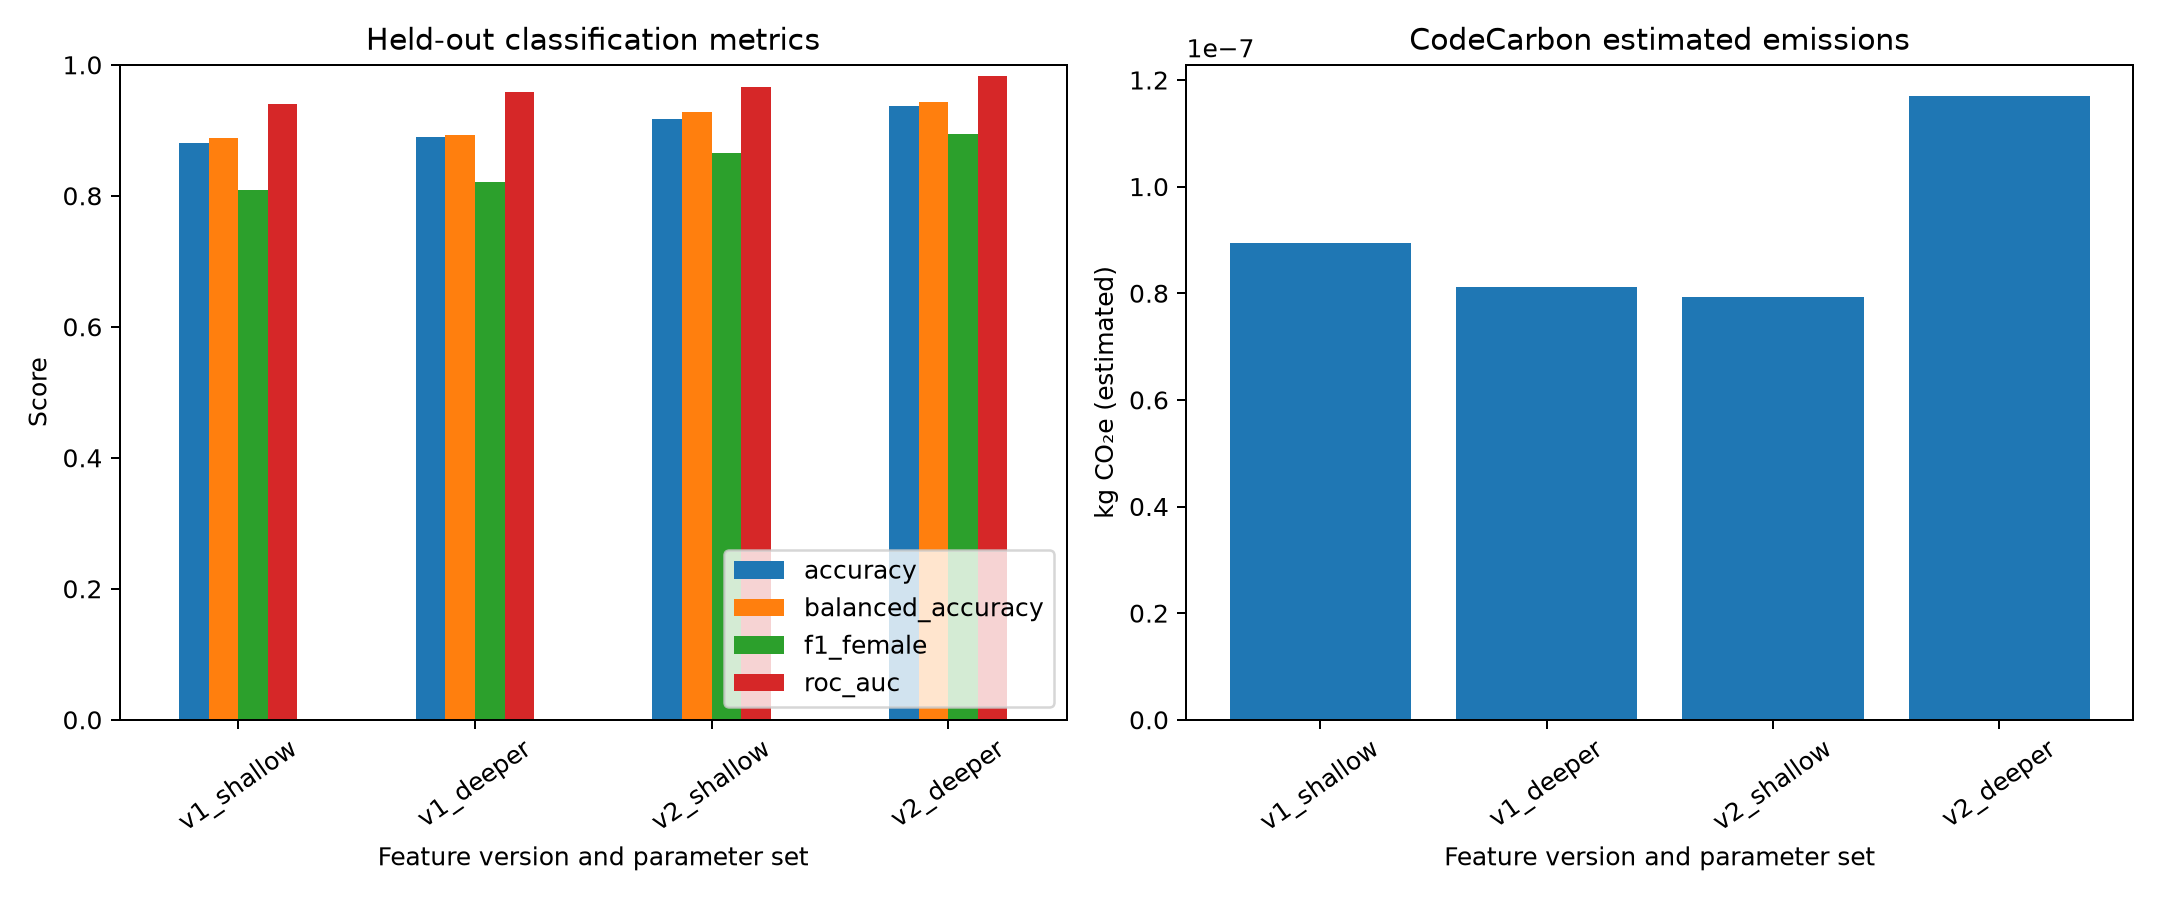

In [3]:
display(Image(filename=str(RUN_DIR / "comparison.png")))

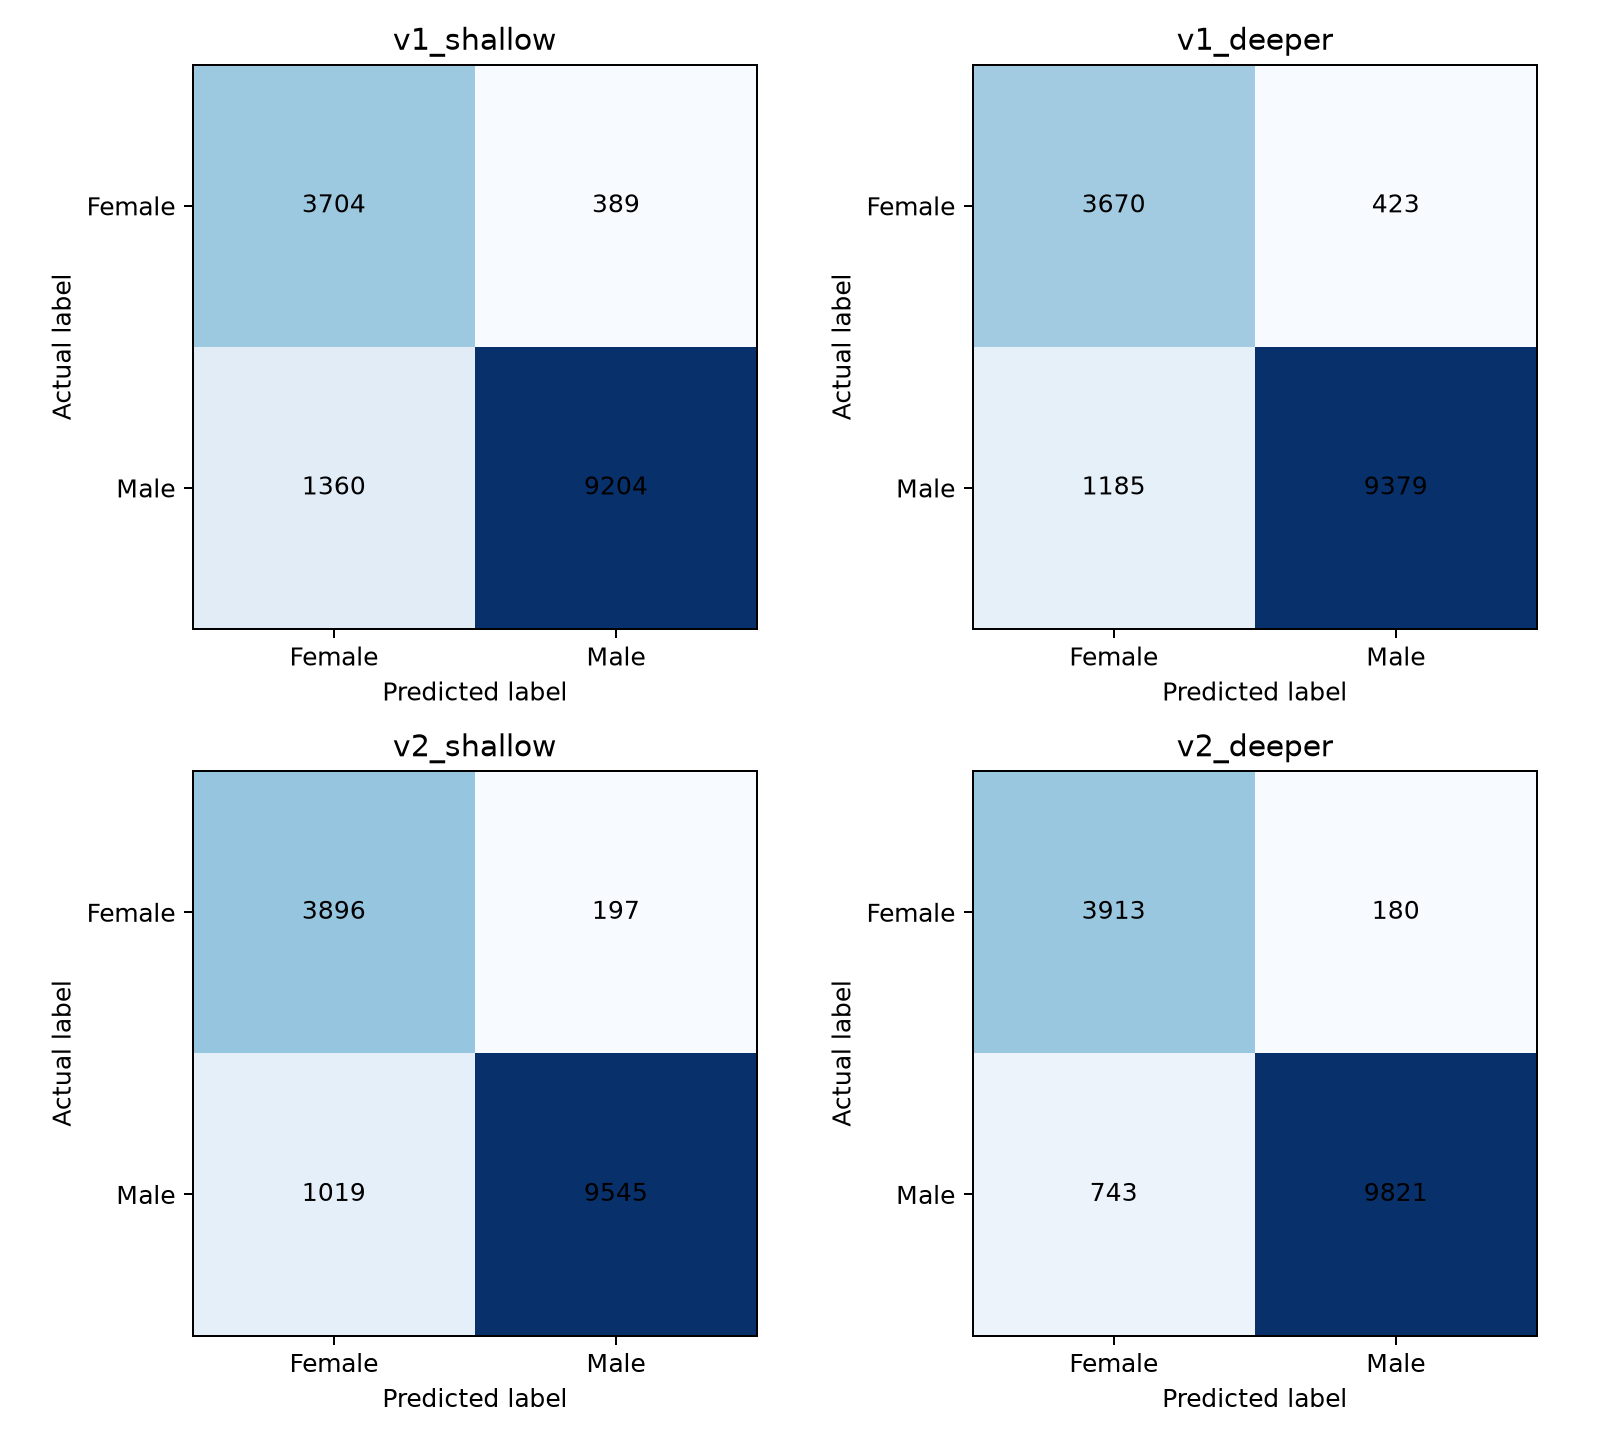

In [4]:
display(Image(filename=str(RUN_DIR / "confusion_matrices.png")))

# CodeCarbon Estimate

CodeCarbon ran in offline mode with the United States national grid mix. It estimated energy and emissions while each model fit and predicted the held-out rows. The recorded run durations are under one second. On this macOS computer, CodeCarbon reported that it could not find a CPU tracking mode and fell back to CPU-load estimation. Its CSV reports CPU utilization as zero for all four sub-second runs, so these estimates should be treated as rough. They are not readings from a power meter, and their tiny differences should not be treated as a meaningful efficiency ranking.

In [5]:
carbon_rows = []
for run_name in results["run_name"]:
    carbon = pd.read_csv(RUN_DIR / "model_runs" / run_name / "codecarbon.csv")
    carbon_rows.append(carbon.iloc[-1])

carbon_summary = pd.DataFrame(carbon_rows)
carbon_columns = [
    "project_name",
    "duration",
    "emissions",
    "energy_consumed",
    "country_name",
    "country_iso_code",
    "tracking_mode",
    "cpu_utilization_percent",
]
carbon_table = carbon_summary[carbon_columns].copy()
for column in ["duration", "emissions", "energy_consumed"]:
    carbon_table[column] = carbon_table[column].map(lambda value: f"{value:.12g}")
display(carbon_table)

,project_name,duration,emissions,energy_consumed,country_name,country_iso_code,tracking_mode,cpu_utilization_percent
0,v1_shallow,0.173261917,8.94664707274e-08,2.42146166912e-07,United States,USA,process,0
0,v1_deeper,0.142292542,8.11825050801e-08,2.19725135748e-07,United States,USA,process,0
0,v2_shallow,0.138271458,7.93290630844e-08,2.14708688008e-07,United States,USA,process,0
0,v2_deeper,0.188195583,1.16998904416e-07,3.16664287827e-07,United States,USA,process,0


# Reproduction

From this folder, install the locked Python 3.12 environment and run:

    uv sync --locked --python 3.12
    uv run python src/run_pipeline.py

The pipeline prepares the local Feast feature views, checks both real feature-service reads, creates the shared split once, then launches one MLflow Project run for each feature-version and hyperparameter-set combination.